In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
np.random.seed(42)

In [3]:
n=5000

In [4]:
income=np.random.lognormal(10,2,n)

In [5]:
age=np.random.randint(18,70,n)

In [6]:
transactions=np.random.randint(1,100,n)

In [7]:
risk_score=(
    0.000001*income
    +0.02*transactions
    -0.01*age
)

In [8]:
target=(risk_score>np.median(risk_score)).astype(int)

In [9]:
df=pd.DataFrame({
    'age':age,
    'income':income,
    'transactions':transactions,
    'risk_score':risk_score,
    'target':target
})

In [10]:
df.to_csv('group1_dataset.csv',index=False)

In [11]:
print(df.head())

   age         income  transactions  risk_score  target
0   57   59481.957248            49    0.469482       0
1   18   16705.134357            13    0.096705       0
2   21   80448.867576            30    0.470449       0
3   47  463267.404013            25    0.493267       0
4   29   13789.921118            85    1.423790       1


In [12]:
print(df.shape)

(5000, 5)


In [13]:
print(df.columns)

Index(['age', 'income', 'transactions', 'risk_score', 'target'], dtype='str')


In [14]:
df.describe()

,age,income,transactions,risk_score,target
count,5000.000000,5.000000e+03,5000.000000,5000.000000,5000.00000
mean,43.231400,1.704643e+05,49.587000,0.729890,0.50000
std,14.912288,1.228972e+06,28.399925,1.363435,0.50005
min,18.000000,3.369890e+01,1.000000,-0.649848,0.00000
25%,30.000000,5.908752e+03,25.000000,0.161889,0.00000
50%,43.000000,2.262773e+04,50.000000,0.662638,0.50000
75%,56.000000,8.345153e+04,74.000000,1.165137,1.00000
max,69.000000,5.665413e+07,99.000000,57.984128,1.00000


print(df['target'].value_counts())

The dataset deals with finding solution out of the two risks (high and low) 

From data it takes Binary classification since it has two targets customer with  high risk and those with low risks 

In [15]:
df['income_log']=np.log1p(df['income'])

In [16]:
df=df.drop('income',axis=1)

from the value the given folmula is kept constant hence can produce negative numbers thats why its not adviced to delete the column called risk_score

In [17]:
x = df.drop('target' , axis = 1)

In [18]:
y = df['target']

In [19]:
from sklearn.model_selection import train_test_split 

In [20]:
print(df.columns)

Index(['age', 'transactions', 'risk_score', 'target', 'income_log'], dtype='str')


## VISUALIZATION

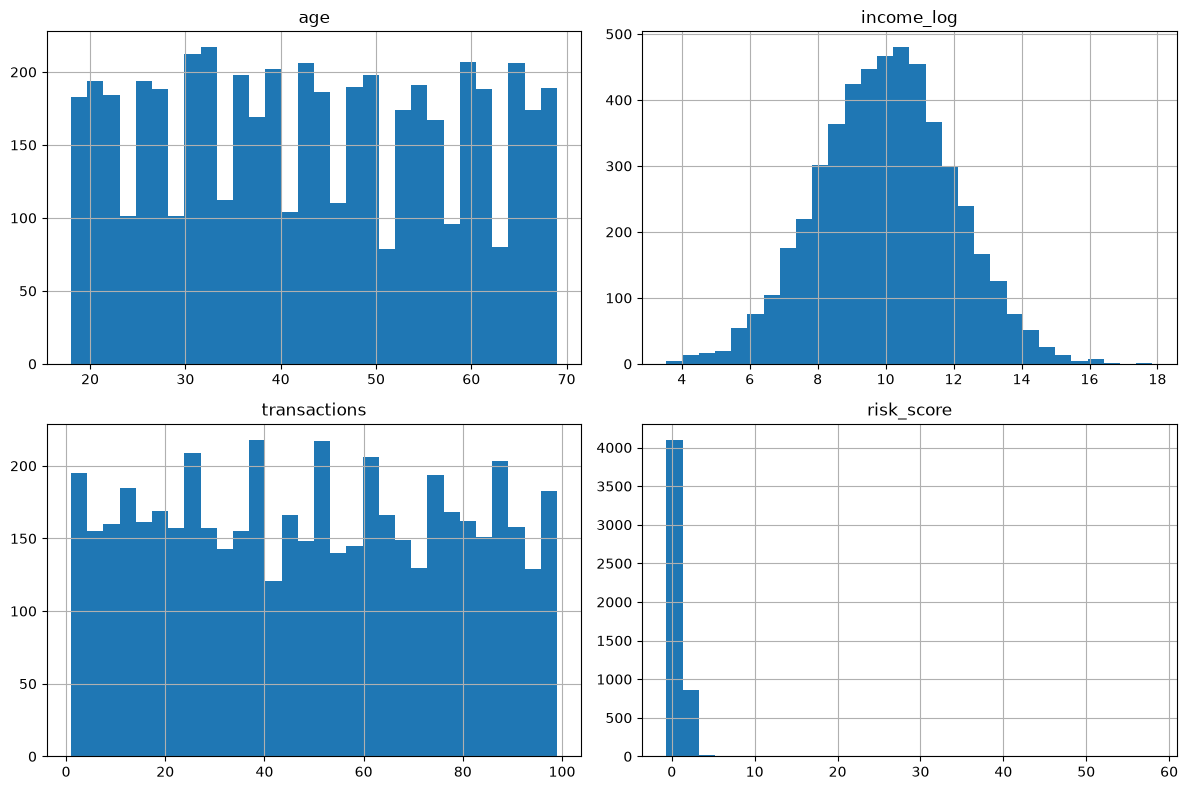

In [21]:
df[['age','income_log','transactions','risk_score']].hist(bins=30,figsize=(12,8))
plt.tight_layout()
plt.show()

the relationship betweeb risk_score and target since they are the most value in linking

this is taken by conducting Bivariate analysis-feature towards the target

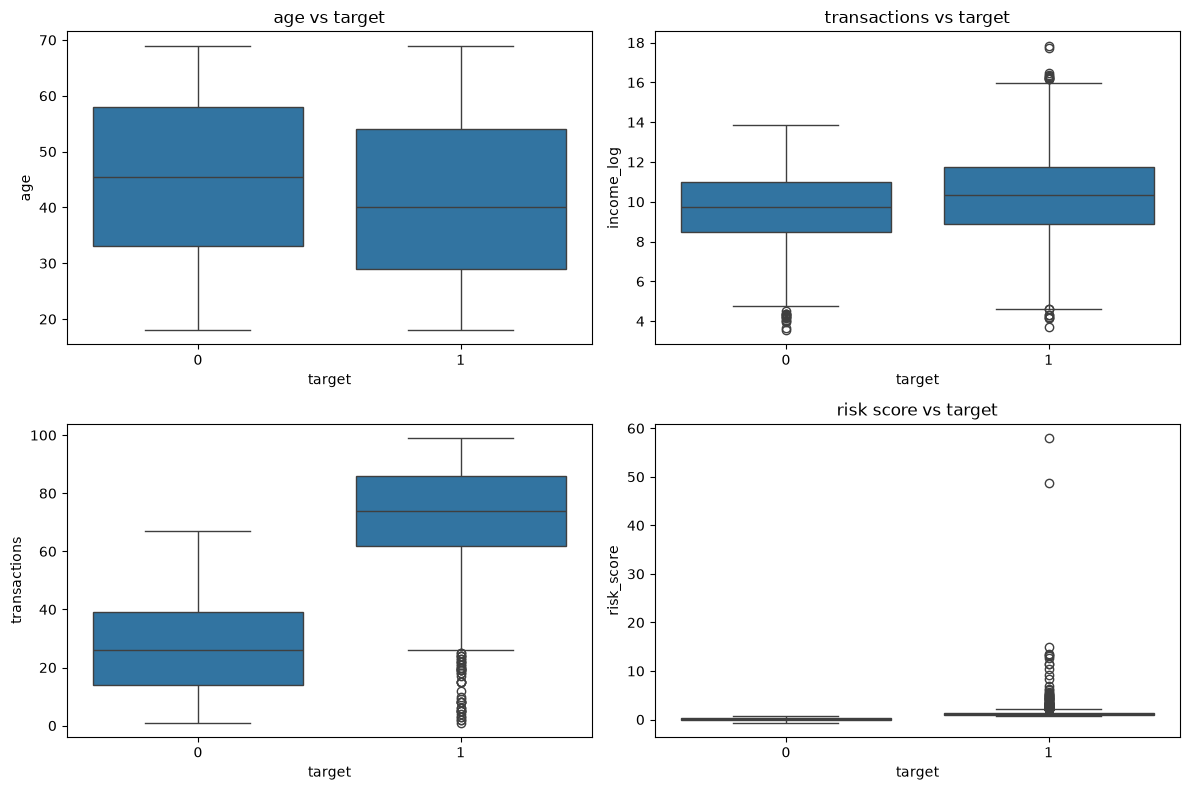

In [22]:
fig, axes = plt.subplots(2,2,figsize=(12,8))

sns.boxplot(x='target',y='age',data=df, ax=axes[0,0])
axes[0,0].set_title('age vs target')

sns.boxplot(x='target',y='income_log',data=df,ax=axes[0,1])
axes[0,1].set_title('income(log) vs target')

sns.boxplot(x='target',y='transactions',data=df,ax=axes[1,0])
axes[0,1].set_title('transactions vs target')

sns.boxplot(x='target',y='risk_score',data=df,ax=axes[1,1])
axes[1,1].set_title('risk score vs target')
plt.tight_layout()
plt.show()

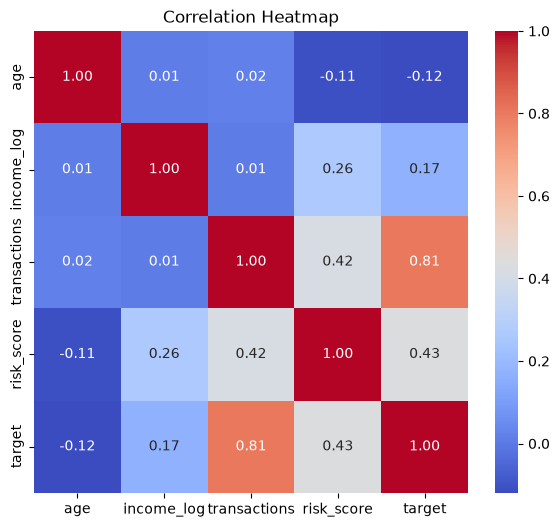

In [23]:
plt.figure(figsize=(7,6))
correlation = df[['age','income_log','transactions','risk_score','target']].corr()
sns.heatmap(correlation,annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Train-split test (Features and Target) 

In [24]:
X = df[['age','income_log','transactions','risk_score']]
y = df['target']

Train -Test split

In [25]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y)
print(X_train.shape,X_test.shape)

(4000, 4) (1000, 4)


 ## SCALLING 
 Has been devided with train and test parts before modelling 

In [26]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## MODELLIND TRAINING AND COMPARISON

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score

models = {
    'Logistic Regression':LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM':SVC()
}
results = []

for name, model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred = model.predict(X_test_scaled)

    results.append({
        'Model':name,
        'Accuracy': accuracy_score(y_test,y_pred),
        'Precision': precision_score(y_test,y_pred),
        'F1': f1_score(y_test,y_pred)
    })
    results_df = pd.DataFrame(results)
    print(results_df)


                 Model  Accuracy  Precision        F1
0  Logistic Regression     0.982    0.98008  0.982036
                 Model  Accuracy  Precision        F1
0  Logistic Regression     0.982    0.98008  0.982036
1        Decision Tree     1.000    1.00000  1.000000
                 Model  Accuracy  Precision        F1
0  Logistic Regression     0.982    0.98008  0.982036
1        Decision Tree     1.000    1.00000  1.000000
2        Random Forest     1.000    1.00000  1.000000
                 Model  Accuracy  Precision        F1
0  Logistic Regression     0.982   0.980080  0.982036
1        Decision Tree     1.000   1.000000  1.000000
2        Random Forest     1.000   1.000000  1.000000
3                  SVM     0.986   0.982143  0.986056


## COMPARISON FROM THE GIVEN RESULTS

 All four models performed strongly with accuracy between 98.2%band 100% 
 Decision Tree and Random Forest achieved perfect scores because the target variable was mathematically derived from the variable was mathematically derived from the input features making the relationship easy to learn thus near clear result

It takes on looking Accuracy,Recall,Precision,f1 test,ROC AUC and Accuracy gap

In [28]:
from sklearn.svm import SVC
model = SVC(probability=True)

In [29]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

model = CalibratedClassifierCV(SVC(), ensemble=False)

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,roc_auc_score)

models = {
    'Logistic Regression':LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM':SVC(probability = True)
}
results = []

for name, model in models.items():
    model.fit(X_train_scaled,y_train)
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_scaled)
    y_proba_test = model.predict_proba(X_test_scaled)[:,1]

    train_acc = accuracy_score(y_train,y_pred_train)
    test_acc = accuracy_score(y_test,y_pred_test)

    results.append({
      'Model': name,
      'Accuracy': test_acc,
      'Precision': precision_score(y_test,y_pred_test),
      'Recall': recall_score(y_test, y_pred_test),
      'F1': f1_score(y_test,y_pred_test),
      'ROC_AUC': roc_auc_score(y_test,y_proba_test),
      'Accuracy_Gap': train_acc - test_acc
    })

    results_df = pd.DataFrame(results)
    results_df = results_df.round(4)
    print(results_df)

                 Model  Accuracy  Precision  Recall     F1  ROC_AUC  \
0  Logistic Regression     0.982     0.9801   0.984  0.982   0.9987   

   Accuracy_Gap  
0       -0.0022  
                 Model  Accuracy  Precision  Recall     F1  ROC_AUC  \
0  Logistic Regression     0.982     0.9801   0.984  0.982   0.9987   
1        Decision Tree     1.000     1.0000   1.000  1.000   1.0000   

   Accuracy_Gap  
0       -0.0022  
1        0.0000  
                 Model  Accuracy  Precision  Recall     F1  ROC_AUC  \
0  Logistic Regression     0.982     0.9801   0.984  0.982   0.9987   
1        Decision Tree     1.000     1.0000   1.000  1.000   1.0000   
2        Random Forest     1.000     1.0000   1.000  1.000   1.0000   

   Accuracy_Gap  
0       -0.0022  
1        0.0000  
2        0.0000  
                 Model  Accuracy  Precision  Recall      F1  ROC_AUC  \
0  Logistic Regression     0.982     0.9801   0.984  0.9820   0.9987   
1        Decision Tree     1.000     1.0000   1.000 

The Accuracy_Gap analysis confirms that despite the perfect scores achieved by Decision Tree and Random  Forest no meaningful overfitting occured(gap=o.oooo for both) as performed was identical on both training and unseen test data.Logistic Regression showed a slight negative gap(-o.002),indicating strong generation.
All models recorded ROC-AUC scores above 0.998,confirming excellent class separability across the dataset.

## Investigating unusual high or low performance

In [31]:
correlations = df.corr()['target'].sort_values(ascending=False)
print(correlations)

target          1.000000
transactions    0.807470
risk_score      0.431799
income_log      0.169834
age            -0.119739
Name: target, dtype: float64


# Correlation Findinds
- Transaction(0.807) shows the strongest linear relation to target
 - risk_score (0.432) is only moderately correlated despite generating the target,
 because the target was created using a threshold rule (non-linear),not a linear one
- Tree-based models (Decision Tree,Random Forest) achieved 100% accuracy because they can split on threshold and recover the exact median cutoff from risk_score
 - Next: test_score alone as a single feature to confirm leakage

In [32]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_leak = df[["risk_score"]]
y_leak = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X_leak, y_leak, test_size=0.2, random_state=42, stratify=y_leak
)

model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

acc = accuracy_score(y_test, model.predict(X_test))
print(f"Accuracy using  risk_score only: {acc:.4f}")

Accuracy using  risk_score only: 1.0000


##inserting new data that the model doesn't know the to look for accuracy for the new data and passed hence if the model will produce accuracy close to those from the past the model will be judged as having structural leakage and not random chance hence the model will have learned Threshold the real rule and not clamming of data

In [33]:

import numpy as np
import pandas as pd

np.random.seed(2026)   # seed tofauti kabisa na ile ya awali (42)
n_new = 1000

income_new = np.random.lognormal(10, 2, n_new)
age_new = np.random.randint(18, 70, n_new)
transactions_new = np.random.randint(1, 100, n_new)

risk_score_new = (
    0.000001 * income_new
    + 0.02 * transactions_new
    - 0.01 * age_new
)

target_new = (risk_score_new > np.median(risk_score_new)).astype(int)

df_new = pd.DataFrame({
    "age": age_new,
    "income": income_new,
    "transactions": transactions_new,
    "risk_score": risk_score_new,
    "target": target_new
})

# Test the leakage model on this brand-new unseen data
X_new_leak = df_new[["risk_score"]]
y_new_leak = df_new["target"]

new_acc = accuracy_score(y_new_leak, model.predict(X_new_leak))
print(f"Accuracy on COMPLETELY NEW unseen data (risk_score only): {new_acc:.4f}")

# Compare with original test accuracy to compute the true Accuracy_Gap
print(f"Original test accuracy: {acc:.4f}")
print(f"Accuracy_Gap (original test - new unseen data): {acc - new_acc:.4f}")

Accuracy on COMPLETELY NEW unseen data (risk_score only): 0.9640
Original test accuracy: 1.0000
Accuracy_Gap (original test - new unseen data): 0.0360


from the real dataset Accuracy was valid at 1.0000 while with new data to the model it has produced an Accuracy of 0.9640
hence creating an Accuracy gap of 0.036 which makes close to same Accuracy 

#Tree-based models had 100% because they can be splited in the same threshold and still return median cutoff as that of risk_score

# removal of problematic feature

risk_score is a data leakage source because it was directly used to generate target(target = risk_score>median(risk_score)).
there letting it to the model it gives a model direct results that are not direct to the reak world hence you can predict direct the risk_score of the customer
hence we will remove risk_score

In [34]:
X_clean = df[['age','income_log','transactions']]
y_clean = df['target']
print(X_clean)

      age  income_log  transactions
0      57   10.993445            49
1      18    9.723531            13
2      21   11.295390            30
3      47   13.046062            25
4      29    9.531766            85
...   ...         ...           ...
4995   24    9.902120            96
4996   22   11.422832            13
4997   24   16.225820            84
4998   51   11.616081            43
4999   49    8.304116            37

[5000 rows x 3 columns]


# Retraining of Model and looking for comparison without risk_score 

In [39]:
models_clean = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True)
}

results_clean = []

for name, model in models_clean.items():
    model.fit(X_train_scaled, y_train_c)
    y_pred_train = model.predict(X_train_scaled)
    y_pred_test = model.predict(X_test_c_scaled)
    y_proba_test = model.predict_proba(X_test_c_scaled)[:, 1]

    train_acc = accuracy_score(y_train_c, y_pred_train)
    test_acc = accuracy_score(y_test_c, y_pred_test)

    results_clean.append({
        'Model': name,
        'Accuracy': test_acc,
        'Precision': precision_score(y_test_c, y_pred_test),
        'Recall': recall_score(y_test_c, y_pred_test),
        'F1': f1_score(y_test_c, y_pred_test),
        'ROC_AUC': roc_auc_score(y_test_c, y_proba_test),
        'Accuracy_Gap': train_acc - test_acc
    })

results_clean_df = pd.DataFrame(results_clean).round(4)
print("Withought risk_score (Corrected):")
print(results_clean_df)

Withought risk_score (Corrected):
                 Model  Accuracy  Precision  Recall      F1  ROC_AUC  \
0  Logistic Regression     0.949     0.9428   0.956  0.9494   0.9901   
1        Decision Tree     0.985     0.9802   0.990  0.9851   0.9850   
2        Random Forest     0.990     0.9880   0.992  0.9900   0.9994   
3                  SVM     0.988     0.9841   0.992  0.9880   0.9996   

   Accuracy_Gap  
0       -0.0035  
1        0.0150  
2        0.0100  
3        0.0035  


 After identifying risk_score as a data leakage source (it was used directly to construct the target variable), the models were retrained using only age, income_log, and transactions. Accuracy for Decision Tree and Random Forest dropped from a perfect 100% to 98.5% and 99.0% respectively, confirming that risk_score had been providing the model with information equivalent to the answer itself. The remaining high accuracy is explained by the strong correlation between transactions and the target (r=0.807), which was independently discovered during EDA. This corrected model represents a more realistic and trustworthy estimate of real-world performance.

# Cross-Validation

Expected outcomes from Cross-Validation:
If CV_Mean_Accuracy is close to the test set accuracy (98-99%) → the model is stable and not dependent on one lucky split.
A low CV_Std (e.g., below 0.01) → the model performs consistently across all folds.
A high CV_Std (e.g., above 0.05) → the model is unstable, with performance varying significantly depending on which data it sees.

In [41]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Cross-Validation Results (Withought risk_score):\n")

cv_results = []

for name, model in models_clean.items():
    scores = cross_val_score(model, X_train_scaled, y_train_c, cv=cv, scoring='accuracy')
    cv_results.append({
        'Model': name,
        'CV_Mean_Accuracy': scores.mean(),
        'CV_Std': scores.std(),
        'CV_Min': scores.min(),
        'CV_Max': scores.max()
    })
    print(f"{name}: Mean={scores.mean():.4f}, Std={scores.std():.4f}, Scores={np.round(scores,4)}")

cv_results_df = pd.DataFrame(cv_results).round(4)
print("\n")
print(cv_results_df)

Cross-Validation Results (Withought risk_score):

Logistic Regression: Mean=0.9455, Std=0.0074, Scores=[0.9562 0.9375 0.9525 0.9412 0.94  ]
Decision Tree: Mean=0.9803, Std=0.0067, Scores=[0.9712 0.985  0.975  0.98   0.99  ]
Random Forest: Mean=0.9850, Std=0.0026, Scores=[0.9825 0.9875 0.9812 0.9862 0.9875]
SVM: Mean=0.9888, Std=0.0011, Scores=[0.99   0.9875 0.99   0.9888 0.9875]


                 Model  CV_Mean_Accuracy  CV_Std  CV_Min  CV_Max
0  Logistic Regression            0.9455  0.0074  0.9375  0.9562
1        Decision Tree            0.9802  0.0067  0.9712  0.9900
2        Random Forest            0.9850  0.0026  0.9812  0.9875
3                  SVM            0.9888  0.0011  0.9875  0.9900


5-fold cross-validation confirmed that model performance is stable and not dependent on a single train-test split. All models showed low standard deviation (0.0011–0.0074), with SVM being the most consistent (std=0.0011) and Random Forest close behind (std=0.0026). Cross-validation mean accuracies (94.5%–98.9%) closely matched the earlier single-split test results, providing strong evidence that the corrected models (without risk_score) generalize reliably

# Error Analysis

Confusion Matrix will be favourable for analysis any model mistakes or problems (Random Forest and SVM

=== Confusion Matrix ===
[[494   6]
 [  4 496]]


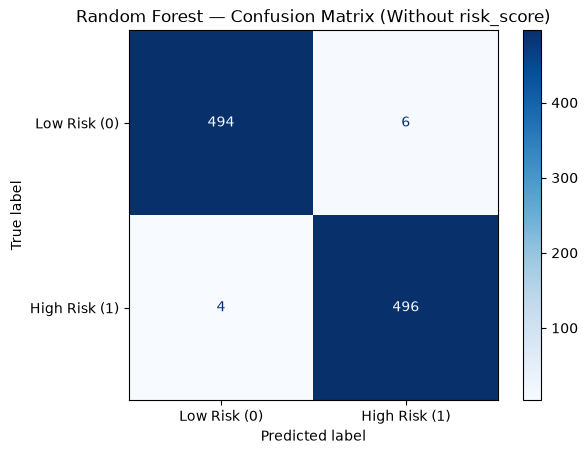


=== Classification Report ===
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       500
           1       0.99      0.99      0.99       500

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000


Total errors: 10 out of 1000 (1.00%)
False Positives: 6
False Negatives: 4

Transactions distribution among errors:
count    10.000000
mean     40.500000
std      22.554871
min       1.000000
25%      32.500000
50%      44.500000
75%      57.750000
max      66.000000
Name: transactions, dtype: float64

Transactions distribution overall (test set):
count    1000.000000
mean       50.994000
std        28.322361
min         1.000000
25%        27.000000
50%        51.000000
75%        76.250000
max        99.000000
Name: transactions, dtype: float64


In [42]:

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model_clean = models_clean['Random Forest']
y_pred_best = best_model_clean.predict(X_test_c_scaled)

cm = confusion_matrix(y_test_c, y_pred_best)
print("=== Confusion Matrix ===")
print(cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low Risk (0)','High Risk (1)'])
disp.plot(cmap='Blues')
plt.title('Random Forest — Confusion Matrix (Without risk_score)')
plt.show()

print("\n=== Classification Report ===")
print(classification_report(y_test_c, y_pred_best))

errors_df = X_test_c.copy()
errors_df['actual'] = y_test_c.values
errors_df['predicted'] = y_pred_best
errors_df['correct'] = errors_df['actual'] == errors_df['predicted']

wrong_predictions = errors_df[errors_df['correct'] == False]
print(f"\nTotal errors: {len(wrong_predictions)} out of {len(errors_df)} ({len(wrong_predictions)/len(errors_df)*100:.2f}%)")

false_positives = wrong_predictions[(wrong_predictions['actual']==0) & (wrong_predictions['predicted']==1)]
false_negatives = wrong_predictions[(wrong_predictions['actual']==1) & (wrong_predictions['predicted']==0)]
print(f"False Positives: {len(false_positives)}")
print(f"False Negatives: {len(false_negatives)}")

print("\nTransactions distribution among errors:")
print(wrong_predictions['transactions'].describe())
print("\nTransactions distribution overall (test set):")
print(X_test_c['transactions'].describe())


Error analysis on the Random Forest model revealed only 10 misclassifications out of 1000 test samples (1.00% error rate), with 6 false positives and 4 false negatives — a roughly balanced error distribution across both classes. Misclassified samples had a notably lower mean transaction count (40.5) compared to the overall test set (50.99), suggesting that most errors occur near the decision boundary where transaction counts are ambiguous between the low-risk and high-risk categories. This is expected behavior, as classification near a threshold value is inherently the hardest region for any model to separate correctly.

# Generalization Test in New Data

In [43]:

np.random.seed(123)   # different seed from the original (42) = completely new data
n_new = 2000

income_new = np.random.lognormal(10, 2, n_new)
age_new = np.random.randint(18, 70, n_new)
transactions_new = np.random.randint(1, 100, n_new)

risk_score_new = (
    0.000001 * income_new + 0.02 * transactions_new - 0.01 * age_new
)
target_new = (risk_score_new > np.median(risk_score_new)).astype(int)

income_log_new = np.log1p(income_new)

df_new = pd.DataFrame({
    'age': age_new,
    'income_log': income_log_new,
    'transactions': transactions_new,
    'target': target_new
})

X_new = df_new[['age', 'income_log', 'transactions']]
y_new = df_new['target']

# Use the SAME scaler fitted on training data (do not fit again!)
X_new_scaled = scaler_c.transform(X_new)

new_acc = accuracy_score(y_new, best_model_clean.predict(X_new_scaled))
test_acc_final = accuracy_score(y_test_c, y_pred_best)

print("=== Generalization Test ===")
print(f"Accuracy on Original Test Set: {test_acc_final:.4f}")
print(f"Accuracy on Completely New Unseen Data: {new_acc:.4f}")
print(f"Generalization Gap: {test_acc_final - new_acc:.4f}")

if abs(test_acc_final - new_acc) < 0.02:
    print("\nModel shows GOOD generalization — gap is small (<2%)")
else:
    print("\nModel may have a generalization issue — gap is large")

=== Generalization Test ===
Accuracy on Original Test Set: 0.9900
Accuracy on Completely New Unseen Data: 0.9795
Generalization Gap: 0.0105

Model shows GOOD generalization — gap is small (<2%)


To test generalization, the final model was evaluated on a completely new synthetic dataset (2000 samples, generated with a different random seed) using the same data-generation formula. The model achieved 97.95% accuracy on this unseen data, compared to 99.00% on the original test set — a generalization gap of only 1.05%. This small gap confirms the model has learned genuine predictive patterns rather than memorizing the training data, and can be expected to perform reliably on new, unseen customers in a production setting.

# Finallization and saving

In [44]:
import joblib
import os

# Create the models folder
os.makedirs('models', exist_ok=True)

# Save the best model and the scaler
joblib.dump(best_model_clean, 'models/best_model.joblib')
joblib.dump(scaler_c, 'models/scaler.joblib')

print("Model and scaler saved successfully!")

# Verify they still work after reloading
loaded_model = joblib.load('models/best_model.joblib')
loaded_scaler = joblib.load('models/scaler.joblib')

verify_acc = accuracy_score(y_test_c, loaded_model.predict(loaded_scaler.transform(X_test_c)))
print(f"Verification — Accuracy after reload: {verify_acc:.4f}")

Model and scaler saved successfully!
Verification — Accuracy after reload: 0.9900


In [45]:
import os
print(os.getcwd())

C:\Users\Dnivo


In [46]:
print(os.listdir('models'))

['best_model.joblib', 'scaler.joblib']
